### 1. Global methane levels from 2002

Methane (CH4) is a naturally occurring Greenhouse Gas (GHG), but one whose abundance has been increased substantially above its pre-industrial value by human activities, primarily because of agricultural emissions (e.g., rice production, ruminants) and fossil fuel production and use. A clear annual cycle is largely due to seasonal wetland emissions.  
Atmospheric methane abundance is indirectly observed by various satellite instruments. These instruments measure spectrally resolved near-infrared and infrared radiation reflected or emitted by the Earth and its atmosphere. In the measured signal, molecular absorption signatures from methane and constituent gasses can be identified. It is through analysis of those absorption lines in these radiance observations that the averaged methane abundance in the sampled atmospheric column can be determined.  
For this problem set, methane levels have been determined by applying several algorithms to different satellite instruments. Download the netCDF4 file (200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc), which contains monthly-averaged methane levels (xch4) in the unit of ppb at each 5° (lon) x 5° (lat) grid over the globe from 2003-01 to 2020-06.

1.1 Compute methane climatology for each month, and plot your results in 12 panels.

In [1]:
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt
import datetime
import warnings
warnings.filterwarnings('ignore')

In [2]:
file_path = r'D:\SUST\ESE\Assignment\Assignment3\200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc'
ds = nc.Dataset(file_path)

time_bnds = ds.variables['time_bnds'][:]
lat = ds.variables['lat'][:]
lon = ds.variables['lon'][:]
xch4_raw = ds.variables['xch4'][:]

In [3]:
xch4_masked = np.ma.masked_where(xch4_raw > 1e10, xch4_raw)     # 异常值清洗
xch4_ppb = xch4_masked * 1e9     # 单位转换，摩尔分数(1e-6)转为 ppb(1e-9)

# 处理时间
time_center = (time_bnds[:, 0] + time_bnds[:, 1]) / 2.0
base = datetime.datetime(1990, 1, 1)
dates = [base + datetime.timedelta(days=float(t)) for t in time_center]
months = np.array([d.month for d in dates])

# 计算月平均
climatology = np.full((12, len(lat), len(lon)), np.nan)
for m in range(1, 13):
    mask = (months == m)
    data_m = xch4_ppb[mask, :, :]
    climatology[m-1] = np.ma.mean(data_m, axis=0).filled(np.nan)

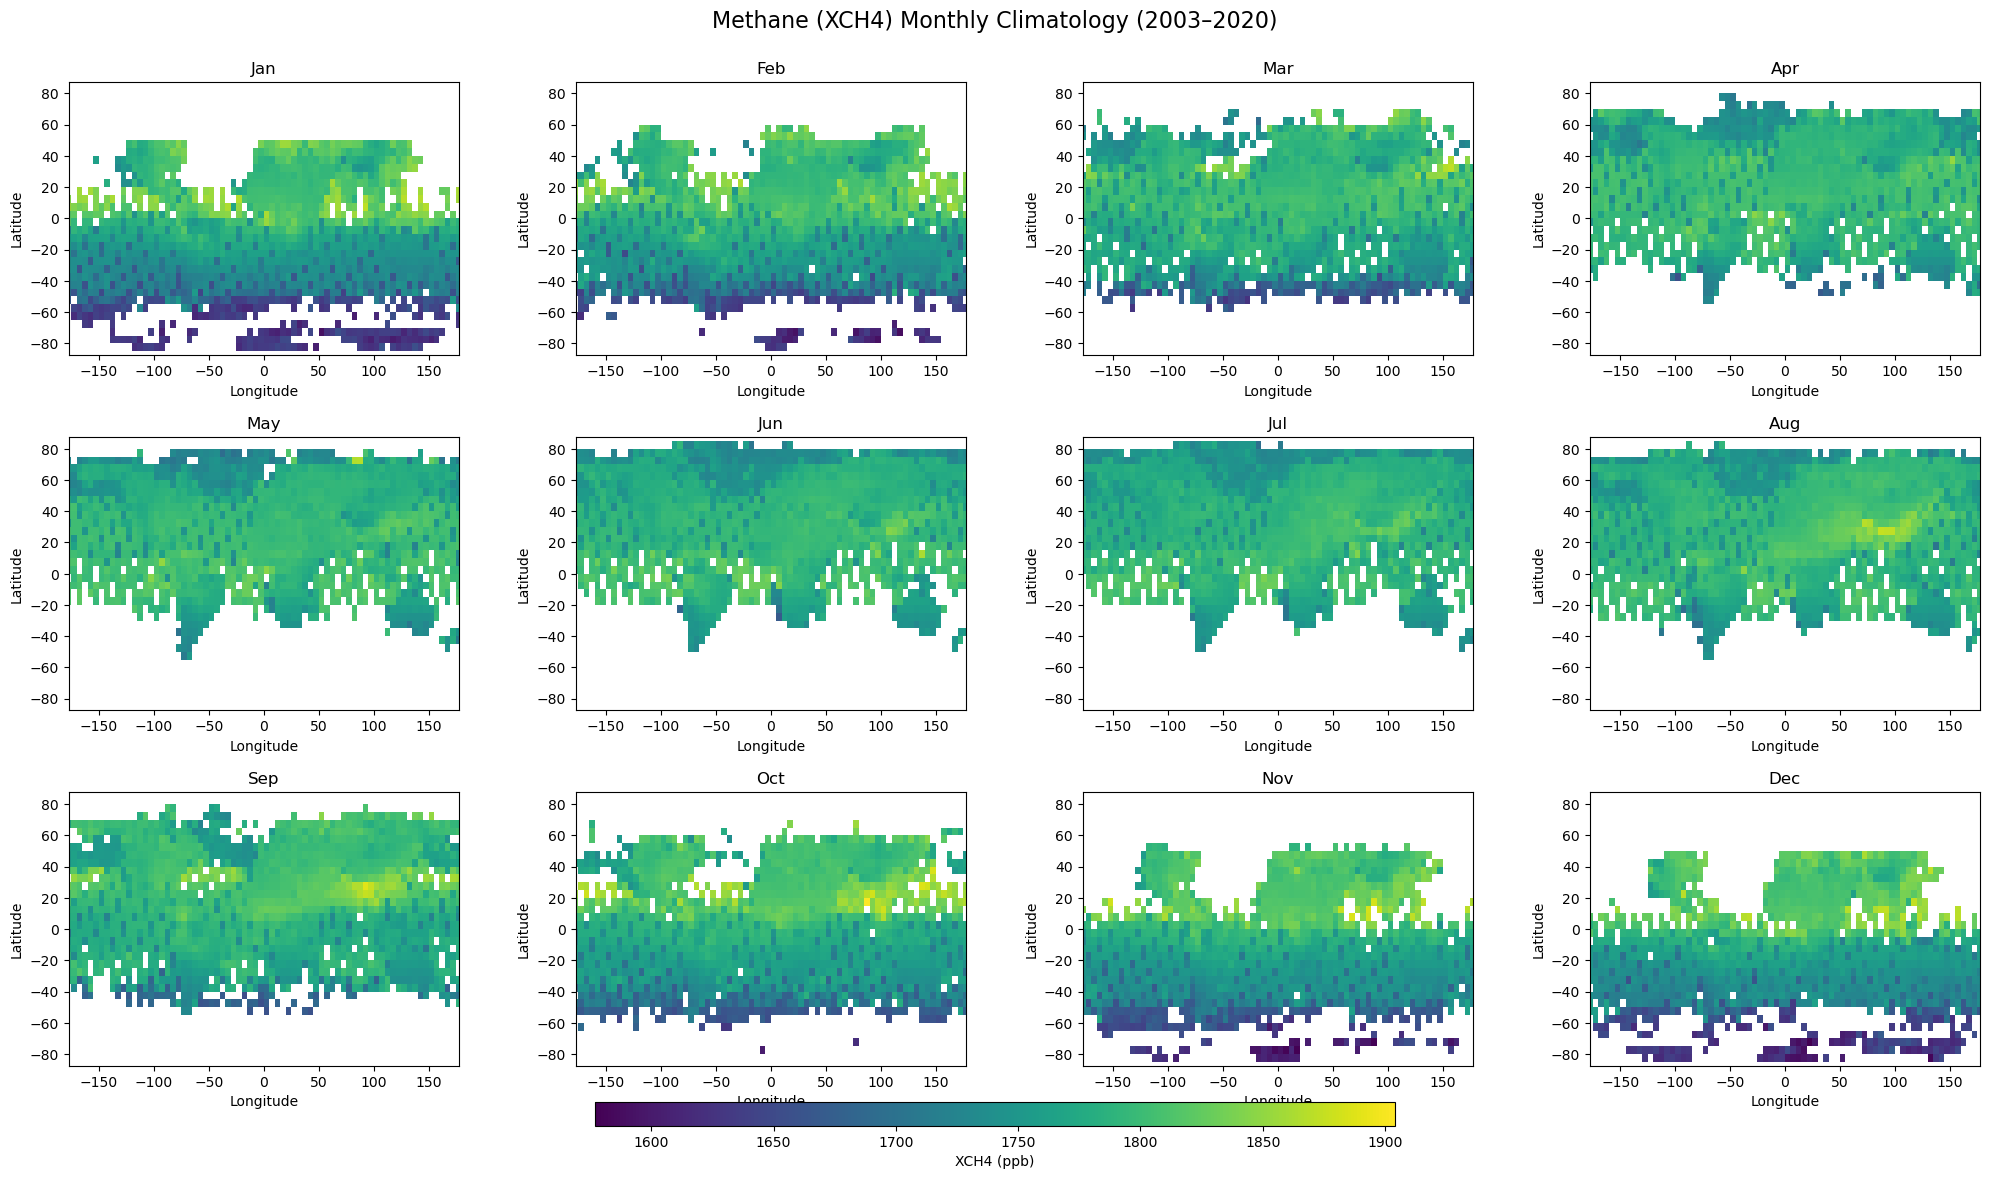

In [4]:
# 画图
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

vmin = np.nanmin(climatology)
vmax = np.nanmax(climatology)

for i, ax in enumerate(axes.flat):
    im = ax.pcolormesh(lon, lat, climatology[i], cmap='viridis',
                       vmin=vmin, vmax=vmax, shading='auto')
    ax.set_title(month_names[i], fontsize=12)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_xlim(lon.min(), lon.max())
    ax.set_ylim(lat.min(), lat.max())

fig.suptitle('Methane (XCH4) Monthly Climatology (2003–2020)', fontsize=16)
fig.tight_layout() 
fig.subplots_adjust(top=0.92, bottom=0.1, hspace=0.3, wspace=0.3)

cax = fig.add_axes([0.3, 0.05, 0.4, 0.02]) 
cb = fig.colorbar(im, cax=cax, orientation='horizontal')
cb.set_label('XCH4 (ppb)')

plt.show()

1.2 Plot globally-averaged methane from 2003-01 to 2020-06 as a time series. Describe your results. Check your plot with this one.

In [5]:
# 计算全球平均 
weights = np.cos(np.deg2rad(lat))
weights = weights.reshape(len(lat), 1)

global_mean = []
for t in range(len(dates)):
    data_t = xch4_ppb[t, :, :]
    mean_val = np.ma.average(data_t, weights=np.tile(weights, (1, len(lon))))
    global_mean.append(mean_val)

global_mean = np.array(global_mean, dtype=float)

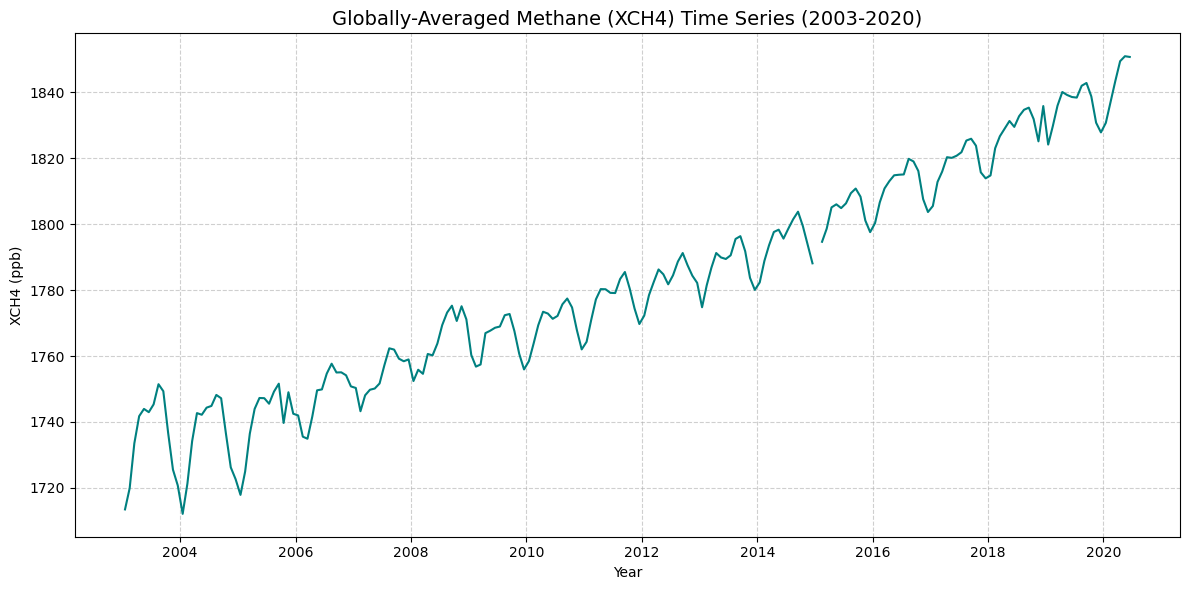

In [6]:
# 画图
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(dates, global_mean, color='teal', linewidth=1.5)

ax.set_title('Globally-Averaged Methane (XCH4) Time Series (2003-2020)', fontsize=14)
ax.set_xlabel('Year')
ax.set_ylabel('XCH4 (ppb)')
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

2003-2020年的全球平均甲烷时间序列呈现出明显的整体上升趋势。该图显示出非线性增长，2003年至2006年的增长率相对较慢甚至略有下降，但在2007年后明显加速。有明显的季节性周期（锯齿状模式），这主要是由湿地排放的季节性变化所驱动的。结果与NOAA参考观测数据高度一致。

1.3 Plot deseasonalized methane levels at point [15°S, 150°W] from 2003-01 to 2020-06 as a time series. Describe your results.

In [7]:
# 目标点 [15°S, 150°W] 最近的索引
target_lat, target_lon = -15.0, -150.0
lat_idx = np.argmin(np.abs(lat - target_lat))
lon_idx = np.argmin(np.abs(lon - target_lon))

ts_raw = xch4_ppb[:, lat_idx, lon_idx]     # 提取原始序列

ts_deseasonalized = np.full(len(dates), np.nan)     # 去季节化

for t in range(len(dates)):
    m = months[t]
    if not np.ma.is_masked(ts_raw[t]):
        ts_deseasonalized[t] = ts_raw[t] - climatology[m-1, lat_idx, lon_idx]     # 原始值 - 对应月份的气候态

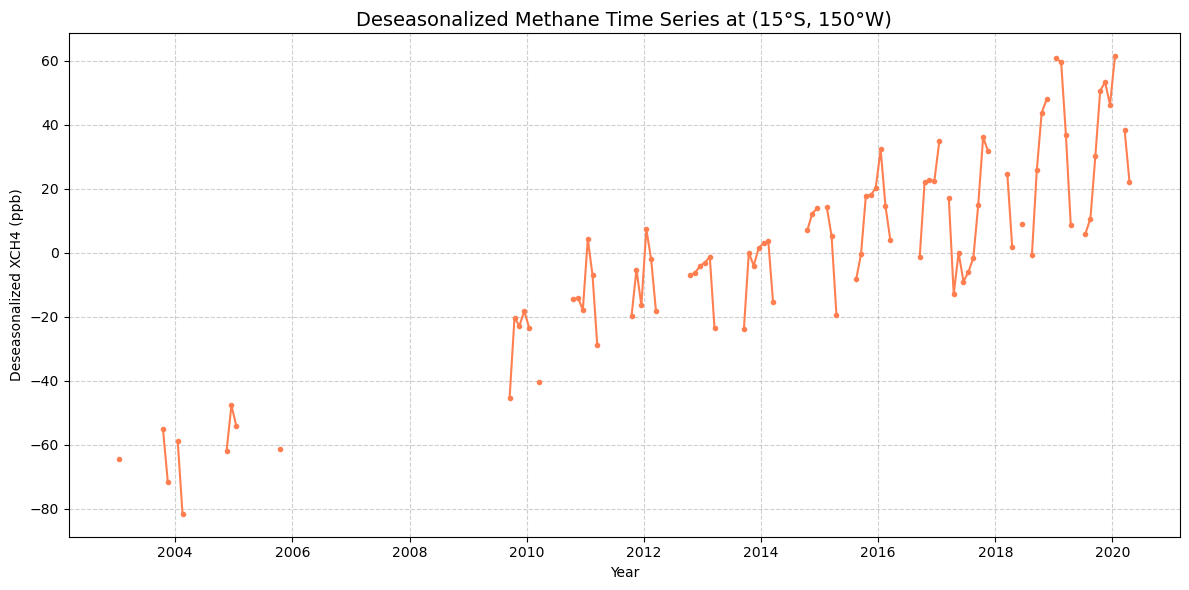

In [8]:
# 画图
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(dates, ts_deseasonalized, color='coral', linewidth=1.5, marker='o', markersize=3)

ax.set_title(f'Deseasonalized Methane Time Series at (15°S, 150°W)', fontsize=14)
ax.set_xlabel('Year')
ax.set_ylabel('Deseasonalized XCH4 (ppb)')
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

该图显示了 2003 年至 2020 年 15°S, 150°W 的去季节化甲烷（XCH4) 时间序列。这一区域原始卫星观测存在明显的数据缺口（不连续性）,特别是在 2006 年至 2009 年左右。现有的去季节性数据点清楚地揭示了从 2004 年的约 -80 ppb 转变为 2020 年的 +40 ppb，这表明该地点背景大气甲烷呈长期增加趋势,与季节周期无关。

### 2. Niño 3.4 index

The Niño 3.4 anomalies may be thought of as representing the average equatorial sea surface temperatures (SSTs) across the Pacific from about the dateline to the South American coast (5N-5S, 170W-120W). The Niño 3.4 index typically uses a 3-month running mean, and El Niño or La Niña events are defined when the Niño 3.4 SSTs exceed +/- 0.5°C for a period of 5 months or more. Check Equatorial Pacific Sea Surface Temperatures for more about the Niño 3.4 index.  
In this problem set, you will use the sea surface temperature (SST) data from NOAA. Download the netCDF4 file (NOAA_NCDC_ERSST_v3b_SST.nc).

2.1 Compute monthly climatology for SST from Niño 3.4 region, and subtract climatology from SST time series to obtain anomalies.

In [9]:
import xarray as xr
import numpy as np

In [10]:
# 读取数据
ds = xr.open_dataset(r'D:\SUST\ESE\Assignment\Assignment3\NOAA_NCDC_ERSST_v3b_SST.nc')
sst = ds["sst"]

In [11]:
if sst.lon.max() > 180:
    sst = sst.assign_coords(lon=(((sst.lon + 180) % 360) - 180)).sortby("lon")     # 经度处理

nino34 = sst.sel(lat=slice(-5, 5), lon=slice(-170, -120))     # 选取 Niño 3.4 区域

# 区域平均
weights = np.cos(np.deg2rad(nino34.lat))
nino34_index = nino34.weighted(weights).mean(dim=["lat", "lon"])

climatology = nino34_index.groupby("time.month").mean("time")     # 计算月气候态

anomaly = nino34_index.groupby("time.month") - climatology     # 计算异常

print(anomaly)

<xarray.DataArray 'sst' (time: 684)> Size: 5kB
array([-3.19667816e-01, -4.68566895e-01, -2.68173218e-01, -1.87026978e-01,
       -1.77633286e-01, -3.57740402e-01, -1.42024994e-01,  1.46179199e-02,
       -1.52324677e-01, -3.79957199e-01, -3.60942841e-01, -2.08698273e-01,
       -1.91465378e-01, -1.34252548e-01, -2.40343094e-01, -1.85153961e-01,
        5.19752502e-02,  2.39477158e-01, -7.02838898e-02, -4.18710709e-01,
       -7.78388977e-01, -7.92448044e-01, -4.96276855e-01, -4.17312622e-01,
       -4.44831848e-01, -4.56037521e-01, -4.36143875e-01, -4.66997147e-01,
       -5.64609528e-01, -4.26921844e-01, -2.76756287e-01, -3.17255020e-01,
       -6.73255920e-01, -6.66164398e-01, -8.17819595e-01, -8.65577698e-01,
       -7.01499939e-01, -3.57099533e-01,  6.96525574e-02,  1.73437119e-01,
       -9.07325745e-02,  7.68928528e-02,  6.87768936e-01,  7.95412064e-01,
        7.13081360e-01,  8.34379196e-01,  9.08708572e-01,  1.08614159e+00,
        8.51741791e-01,  5.23544312e-01, -1.30519867e

2.2 Visualize the computed Niño 3.4. Your plot should look similar to this one.

In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

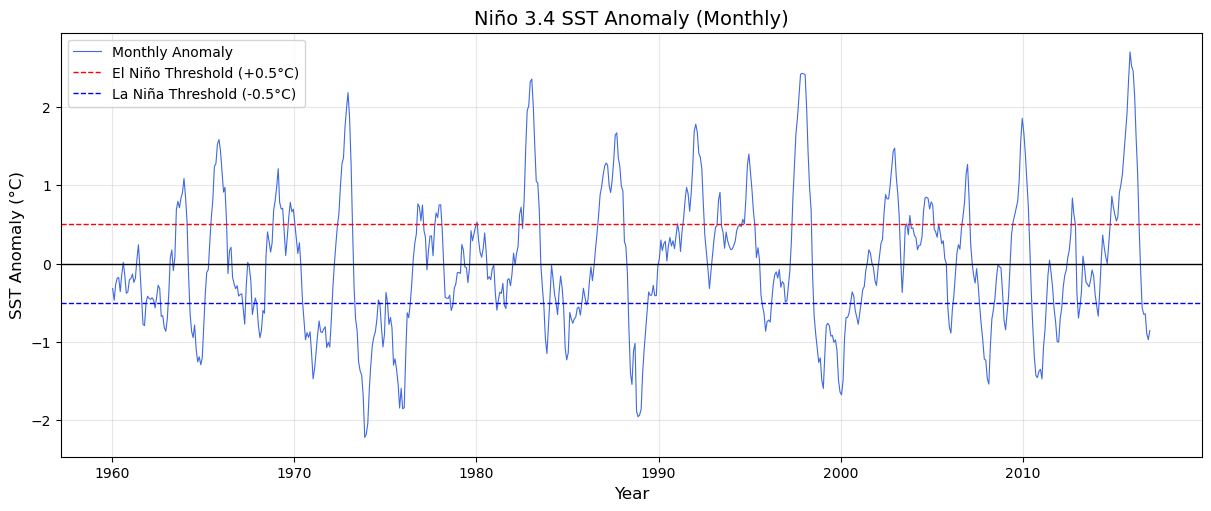

In [13]:
# 画图
fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)

ax.plot(anomaly.time, anomaly, color='royalblue', linewidth=0.8, label='Monthly Anomaly')     # 绘制月度异常线

ax.axhline(0, color='black', linewidth=1)     # 0°C 基准线

# ±0.5°C 的厄尔尼诺/拉尼娜阈值线
ax.axhline(0.5, color='red', linestyle='--', linewidth=1, label='El Niño Threshold (+0.5°C)')
ax.axhline(-0.5, color='blue', linestyle='--', linewidth=1, label='La Niña Threshold (-0.5°C)')

ax.set_title("Niño 3.4 SST Anomaly (Monthly)", fontsize=14)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("SST Anomaly (°C)", fontsize=12)
ax.xaxis.set_major_locator(mdates.YearLocator(10))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.grid(alpha=0.3)
ax.legend(loc='upper left')

plt.show()

### 3. Explore a netCDF dataset

Browse the NASA’s Goddard Earth Sciences Data and Information Services Center (GES DISC) website. Search and download a dataset you are interested in. You are also welcome to use data from your group in this problem set. But the dataset should be in netCDF format, and have temporal information.

3.1 Plot a time series of a certain variable with monthly seasonal cycle removed.

选用了自己的 NCEP/NCAR Reanalysis 月度平均气温数据（0.995 sigma 层），来自 NOAA ESRL PSD。

In [14]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [15]:
# 读取数据
ds = xr.open_dataset(r"D:\SUST\ESE\Assignment\Assignment3\air.sig995.mon.mean.nc")
air = ds["air"]

In [16]:
point = air.sel(lat=40, lon=116, method="nearest")     # 格点选取

# 去月季节循环
clim = point.groupby("time.month").mean("time")
anom = point.groupby("time.month") - clim

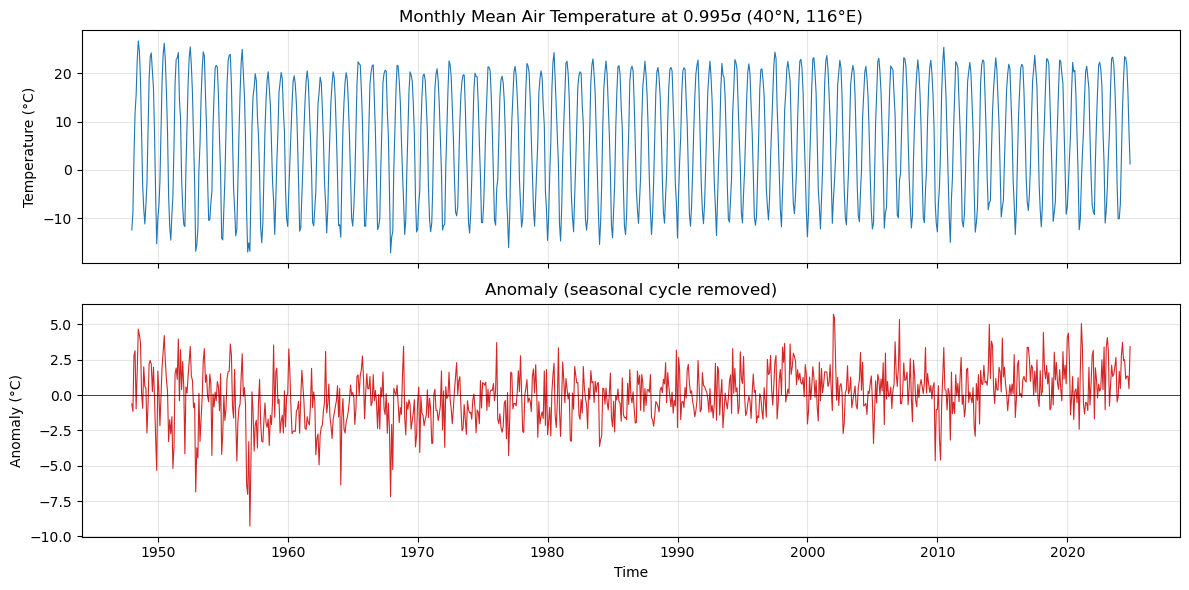

In [17]:
# 画图
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(point["time"], point, color="tab:blue", lw=0.8)
axes[0].set_title("Monthly Mean Air Temperature at 0.995σ (40°N, 116°E)")
axes[0].set_ylabel("Temperature (°C)")
axes[0].grid(alpha=0.3)

axes[1].plot(anom["time"], anom, color="tab:red", lw=0.8)
axes[1].axhline(0, color="k", lw=0.5)
axes[1].set_title("Anomaly (seasonal cycle removed)")
axes[1].set_ylabel("Anomaly (°C)")
axes[1].set_xlabel("Time")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("fig_3_1_timeseries.png", dpi=150)
plt.show()

3.2 Make at least 5 different plots using the dataset.

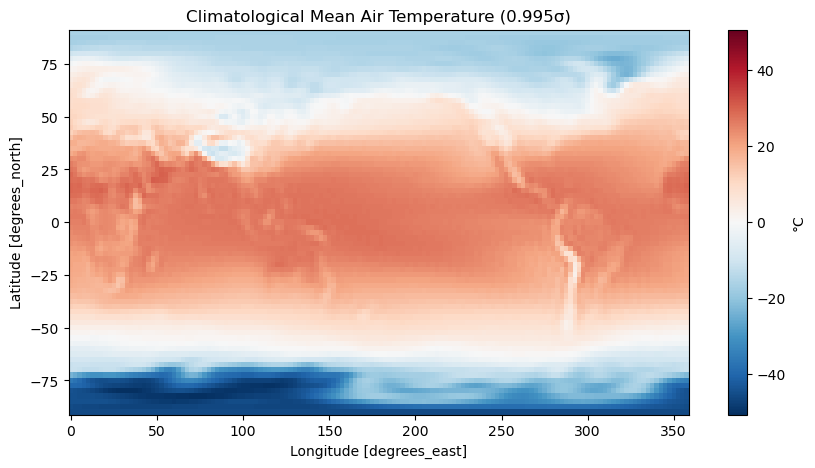

In [18]:
# 1) 全球气候态多年平均气温图（空间场）
fig, ax = plt.subplots(figsize=(10, 5))
mean_air = air.mean("time")
mean_air.plot(ax=ax, cmap="RdBu_r", cbar_kwargs={"label": "°C"})
ax.set_title("Climatological Mean Air Temperature (0.995σ)")
plt.savefig("fig_3_2_1_climatology.png", dpi=150)
plt.show()

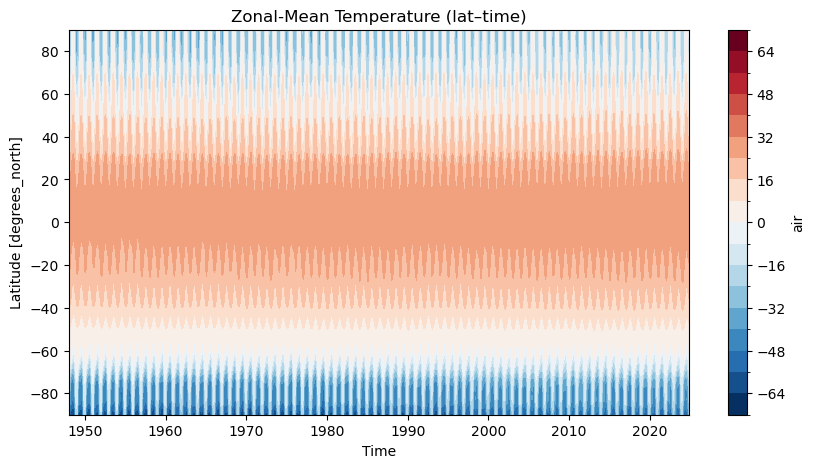

In [19]:
# 2) Hovmöller 图：纬度-时间（经向平均）
fig, ax = plt.subplots(figsize=(10, 5))
air.mean("lon").plot.contourf(ax=ax, x="time", y="lat",
                              levels=20, cmap="RdBu_r")
ax.set_title("Zonal-Mean Temperature (lat–time)")
plt.savefig("fig_3_2_2_hovmoller.png", dpi=150)
plt.show()

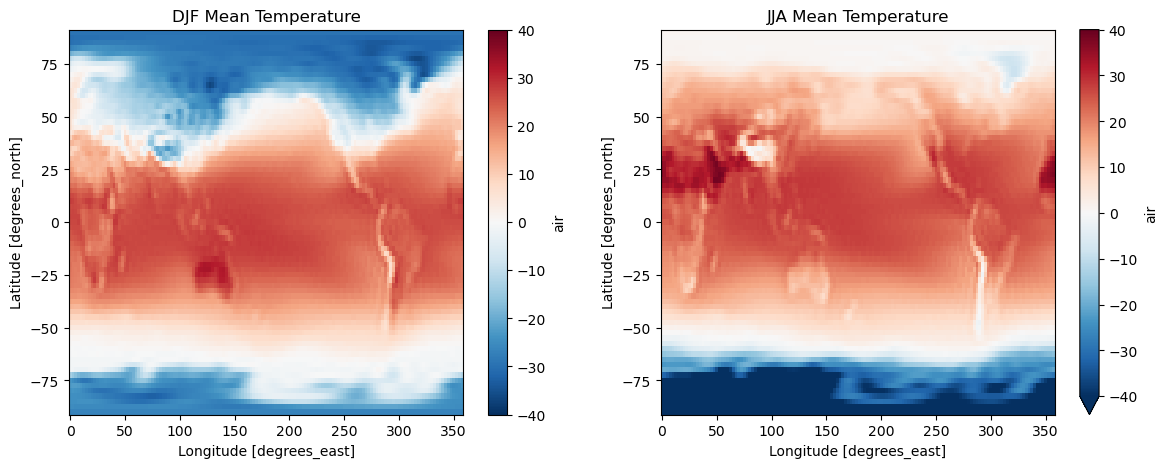

In [20]:
# 3) 季节平均图：DJF / JJA 全球分布
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, season, months in zip(axes, ["DJF", "JJA"], [[12,1,2],[6,7,8]]):
    s = air.sel(time=air["time.month"].isin(months)).mean("time")
    s.plot(ax=ax, cmap="RdBu_r", vmin=-40, vmax=40)
    ax.set_title(f"{season} Mean Temperature")
plt.savefig("fig_3_2_3_seasonal.png", dpi=150)
plt.show()

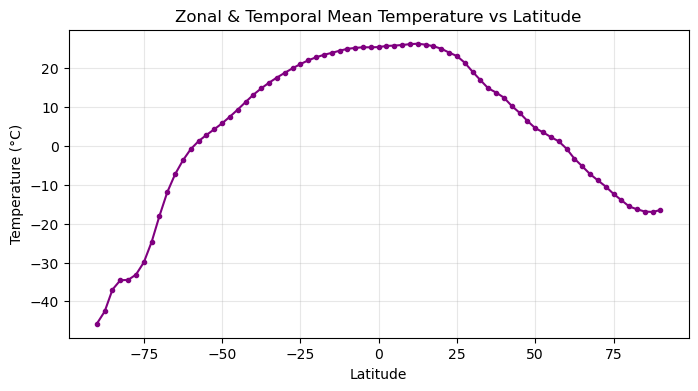

In [21]:
# 4) 纬向平均廓线
fig, ax = plt.subplots(figsize=(8, 4))
air.mean(["time", "lon"]).plot(ax=ax, marker="o", ms=3, color="purple")
ax.set_xlabel("Latitude"); ax.set_ylabel("Temperature (°C)")
ax.set_title("Zonal & Temporal Mean Temperature vs Latitude")
ax.grid(alpha=0.3)
plt.savefig("fig_3_2_4_zonal_profile.png", dpi=150)
plt.show()

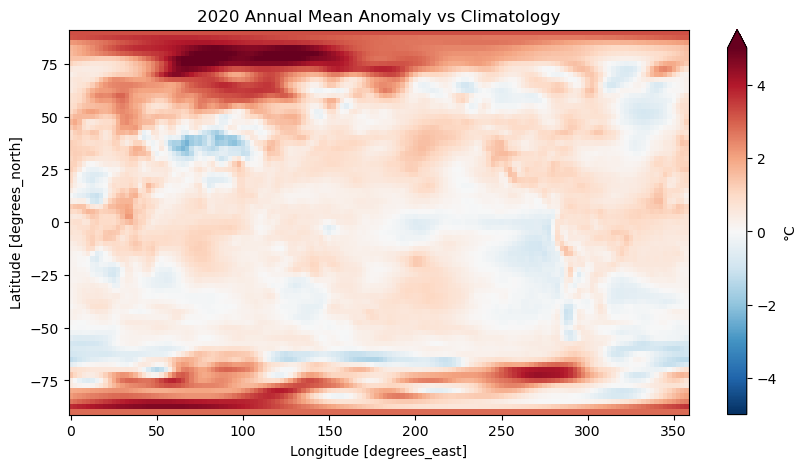

In [22]:
# 5) 某年与气候态的差异（异常场，空间）
year = 2020
anom_field = air.sel(time=str(year)).mean("time") - air.mean("time")
fig, ax = plt.subplots(figsize=(10, 5))
anom_field.plot(ax=ax, cmap="RdBu_r", vmin=-5, vmax=5, cbar_kwargs={"label": "°C"})
ax.set_title(f"{year} Annual Mean Anomaly vs Climatology")
plt.savefig("fig_3_2_5_anomaly_map.png", dpi=150)
plt.show()